# U.S. Recession Forecasting — Model Interpretation

This notebook interprets the recession-forecasting models developed in the previous stage.

The aim is not only to identify which features the models use, but also to understand how the models behave, where they disagree, and why the holdout results are difficult to interpret with very few recession observations.

The reusable model definitions are stored in `src/models.py`; this notebook focuses on interpretation, visualization, and discussion.


In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

from src.models import (
    build_logistic_model,
    build_random_forest_model,
    build_xgboost_model,
)

try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP is not installed. SHAP plots will be skipped.")


## 1. Recreate the Modeling Setup

The same chronological split and model specifications from the modeling notebook are recreated here so that the interpretation corresponds directly to the evaluated models. Model construction is imported from `src/models.py` to keep the specifications consistent across notebooks.


In [2]:
df = pd.read_csv(
    PROJECT_ROOT / "data" / "processed" / "recession_features_6m.csv",
    index_col=0,
    parse_dates=True
)

X = df.drop(columns="target")
y = df["target"].astype(int)

split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Dataset:", df.shape)
print("Training period:", X_train.index.min().date(), "to", X_train.index.max().date())
print("Test period:", X_test.index.min().date(), "to", X_test.index.max().date())
print("Holdout recession observations:", int(y_test.sum()))


Dataset: (469, 24)
Training period: 1987-01-01 to 2018-03-01
Test period: 2018-04-01 to 2026-02-01
Holdout recession observations: 2


In [3]:
logistic_model = build_logistic_model()
random_forest = build_random_forest_model()
xgb_model = build_xgboost_model(y_train)

logistic_model.fit(X_train, y_train)
random_forest.fit(X_train, y_train)
xgb_model.fit(X_train, y_train)

logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
rf_prob = random_forest.predict_proba(X_test)[:, 1]
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]


## 2. Summary of the Observed Modeling Results

The chronological holdout contained only two positive recession targets. This means that metrics such as recall and F1 can change sharply depending on only a few observations.

The results from the modeling notebook were:

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC | PR-AUC |
|---|---:|---:|---:|---:|---:|---:|
| Baseline | 0.979 | 0.000 | 0.000 | 0.000 | 0.500 | 0.021 |
| Logistic Regression | 0.436 | 0.036 | 1.000 | 0.070 | 0.522 | 0.032 |
| Random Forest | 0.936 | 0.000 | 0.000 | 0.000 | 0.500 | 0.030 |
| XGBoost | 0.851 | 0.000 | 0.000 | 0.000 | 0.321 | 0.023 |

The baseline result demonstrates why accuracy is not an appropriate primary metric for this problem. Predicting expansion almost all the time produces very high accuracy because recession targets are rare.

Logistic Regression behaved very differently from the tree models. It detected both positive holdout observations, but its low precision indicates that it also produced many false recession warnings. Random Forest and XGBoost were more conservative at the default 0.5 threshold and did not identify either positive holdout observation.

The cross-validation results were also unstable across historical periods. Two folds contained only one target class and could not be used for all classification metrics. Among the usable folds, model performance changed substantially, indicating that relationships learned in one economic period do not necessarily transfer cleanly to another.


In [4]:
cv_results_actual = pd.DataFrame([
    ["Logistic Regression", 2, 0.000, 0.000, 0.000, 0.641071, 0.141112],
    ["Logistic Regression", 3, 0.000, 0.000, 0.000, 0.732407, 0.346187],
    ["Logistic Regression", 5, 0.000, 0.000, 0.000, 0.355263, 0.029285],
    ["Random Forest", 2, 0.000, 0.000, 0.000, 0.793750, 0.244583],
    ["Random Forest", 3, 1.000, 0.111111, 0.200000, 0.937037, 0.814989],
    ["Random Forest", 5, 0.000, 0.000, 0.000, 0.148026, 0.022282],
    ["XGBoost", 2, 0.000, 0.000, 0.000, 0.520536, 0.112100],
    ["XGBoost", 3, 1.000, 0.166667, 0.285714, 0.950926, 0.835503],
    ["XGBoost", 5, 0.000, 0.000, 0.000, 0.171053, 0.022990]
], columns=[
    "Model", "Fold", "Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"
])

cv_results_actual


,Model,Fold,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Logistic Regression,2,0.0,0.000000,0.000000,0.641071,0.141112
1,Logistic Regression,3,0.0,0.000000,0.000000,0.732407,0.346187
2,Logistic Regression,5,0.0,0.000000,0.000000,0.355263,0.029285
3,Random Forest,2,0.0,0.000000,0.000000,0.793750,0.244583
4,Random Forest,3,1.0,0.111111,0.200000,0.937037,0.814989
5,Random Forest,5,0.0,0.000000,0.000000,0.148026,0.022282
6,XGBoost,2,0.0,0.000000,0.000000,0.520536,0.112100
7,XGBoost,3,1.0,0.166667,0.285714,0.950926,0.835503
8,XGBoost,5,0.0,0.000000,0.000000,0.171053,0.022990


In [5]:
cv_results_actual.groupby("Model")[
    ["Precision", "Recall", "F1", "ROC-AUC", "PR-AUC"]
].agg(["mean", "std"]).round(3)


Precision        Recall            F1        ROC-AUC  \
                         mean    std   mean    std   mean    std    mean   
Model                                                                      
Logistic Regression     0.000  0.000  0.000  0.000  0.000  0.000   0.576   
Random Forest           0.333  0.577  0.037  0.064  0.067  0.115   0.626   
XGBoost                 0.333  0.577  0.056  0.096  0.095  0.165   0.548   

                           PR-AUC         
                       std   mean    std  
Model                                     
Logistic Regression  0.197  0.172  0.161  
Random Forest        0.420  0.361  0.409  
XGBoost              0.391  0.324  0.446

## 3. Logistic Regression Coefficients

Because the Logistic Regression model uses standardized predictors, its coefficients can be compared more directly across features.

A positive coefficient means that, holding the other variables constant, higher values of that feature are associated with a higher predicted probability of recession six months later. A negative coefficient means the opposite.

The coefficients describe the fitted model; they should not be interpreted as causal effects.


In [6]:
logistic_coefficients = pd.Series(
    logistic_model.named_steps["model"].coef_[0],
    index=X.columns
).sort_values()

logistic_coefficients


unemployment_rate                  -2.355369
yield_spread_10y_3m                -1.669814
housing_starts_change_12m          -1.464871
consumer_sentiment_change_6m       -0.933497
industrial_production_growth_12m   -0.863545
initial_claims                     -0.672539
unemployment_change_3m             -0.628049
yield_curve_inverted_10y_2y        -0.589909
credit_spread_change_6m            -0.422565
yield_curve_inverted_10y_3m        -0.412436
housing_starts_change_3m           -0.359871
consumer_sentiment_change_3m       -0.052233
unemployment_change_6m             -0.037815
consumer_sentiment                  0.030857
yield_spread_10y_2y                 0.051078
initial_claims_change_3m            0.072921
credit_spread_change_3m             0.397478
industrial_production_growth_3m     0.406605
initial_claims_change_6m            0.410583
fed_funds_rate                      0.680193
credit_spread                       1.038794
inflation_yoy                       1.198388
unemployme

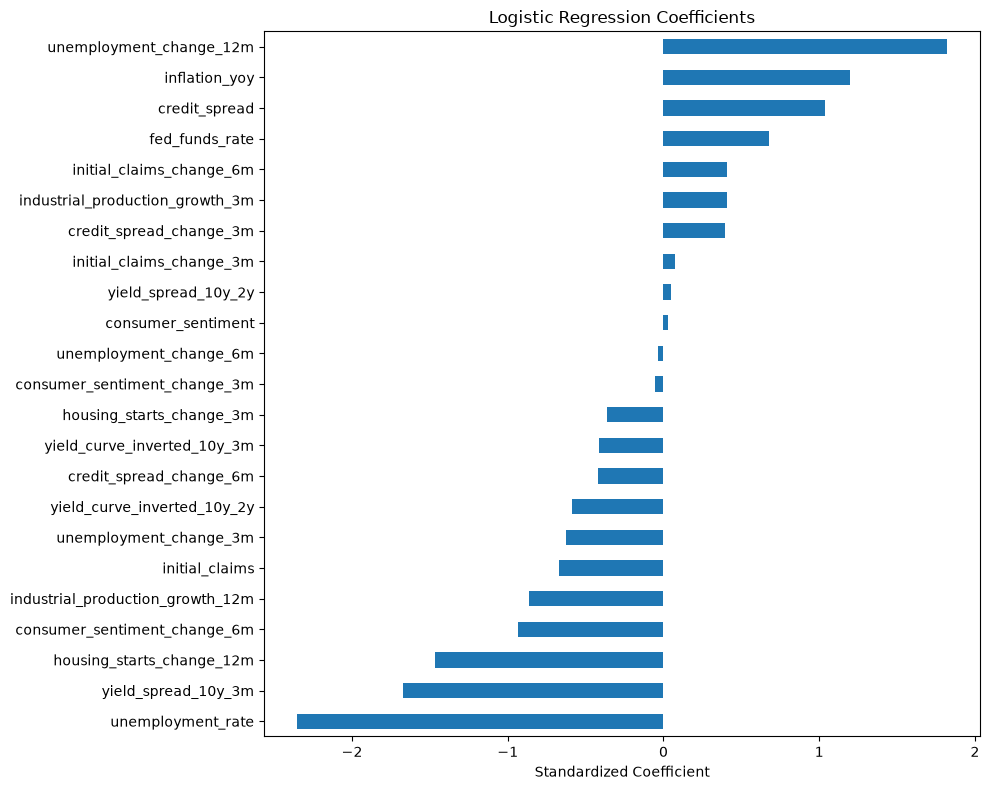

In [7]:
plt.figure(figsize=(10, 8))

logistic_coefficients.plot(kind="barh")

plt.title("Logistic Regression Coefficients")
plt.xlabel("Standardized Coefficient")
plt.ylabel("")

plt.tight_layout()
plt.show()


The largest positive and negative coefficients show which standardized features most strongly influence the linear model's recession probability. Correlated predictors can share or redistribute coefficient weight, so coefficient magnitude should be interpreted cautiously rather than as a definitive ranking of economic importance.


In [8]:
logistic_coefficient_summary = pd.DataFrame({
    "Coefficient": logistic_coefficients,
    "Absolute coefficient": logistic_coefficients.abs()
}).sort_values("Absolute coefficient", ascending=False)

logistic_coefficient_summary.head(10)


,Coefficient,Absolute coefficient
unemployment_rate,-2.355369,2.355369
unemployment_change_12m,1.823442,1.823442
yield_spread_10y_3m,-1.669814,1.669814
housing_starts_change_12m,-1.464871,1.464871
inflation_yoy,1.198388,1.198388
credit_spread,1.038794,1.038794
consumer_sentiment_change_6m,-0.933497,0.933497
industrial_production_growth_12m,-0.863545,0.863545
fed_funds_rate,0.680193,0.680193
initial_claims,-0.672539,0.672539


## 4. Random Forest Feature Importance

Random Forest provides impurity-based feature importance. This measures how much each feature contributes to reducing classification impurity across the trees.

Unlike Logistic Regression coefficients, these values do not indicate whether a feature raises or lowers recession probability. They only indicate how frequently and effectively the feature is used in tree splits.

Impurity-based importance can also favor continuous variables with many possible split points, so the results are treated as descriptive rather than causal.


In [9]:
rf_importance = pd.Series(
    random_forest.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

rf_importance.head(10)


unemployment_change_12m             0.151516
initial_claims_change_6m            0.116177
housing_starts_change_12m           0.106050
initial_claims_change_3m            0.079121
inflation_yoy                       0.068997
unemployment_change_6m              0.068244
consumer_sentiment_change_6m        0.065904
industrial_production_growth_12m    0.052018
industrial_production_growth_3m     0.042791
fed_funds_rate                      0.032649
dtype: float64

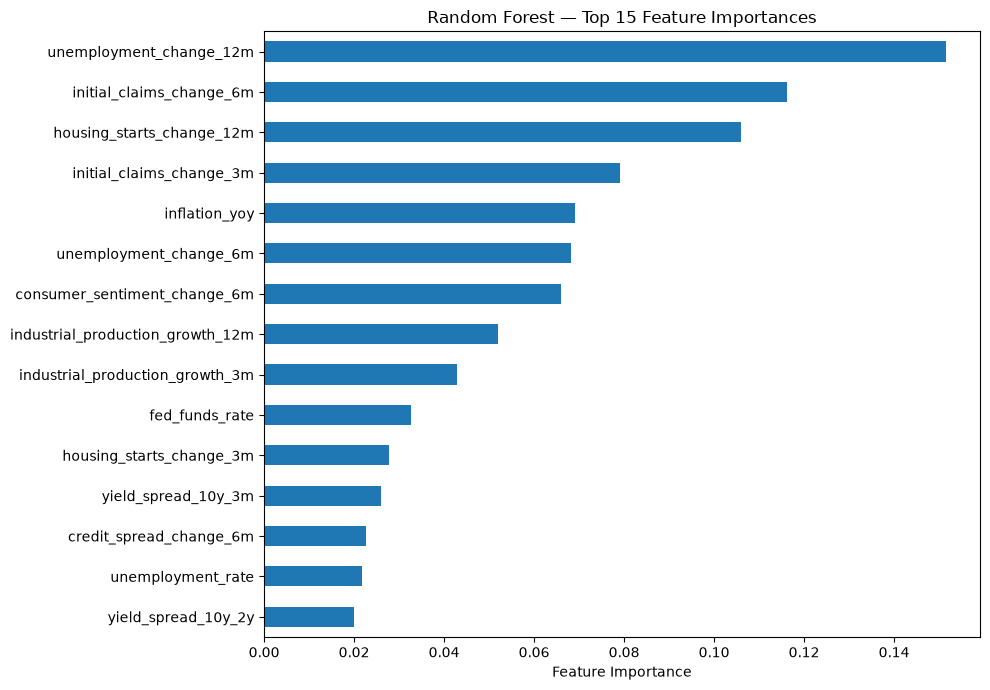

In [10]:
plt.figure(figsize=(10, 7))

rf_importance.head(15).sort_values().plot(kind="barh")

plt.title("Random Forest — Top 15 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("")

plt.tight_layout()
plt.show()


## 5. XGBoost Feature Importance

The fitted XGBoost model also provides tree-based feature importance. This gives a first view of which engineered indicators were useful to the boosted trees before using SHAP for more detailed interpretation.


In [11]:
xgb_importance = pd.Series(
    xgb_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

xgb_importance.head(10)


unemployment_change_12m             0.211796
initial_claims_change_6m            0.146440
housing_starts_change_12m           0.116398
initial_claims_change_3m            0.091961
consumer_sentiment_change_6m        0.046089
unemployment_change_6m              0.043932
inflation_yoy                       0.043683
industrial_production_growth_12m    0.040131
yield_spread_10y_3m                 0.034406
fed_funds_rate                      0.028038
dtype: float32

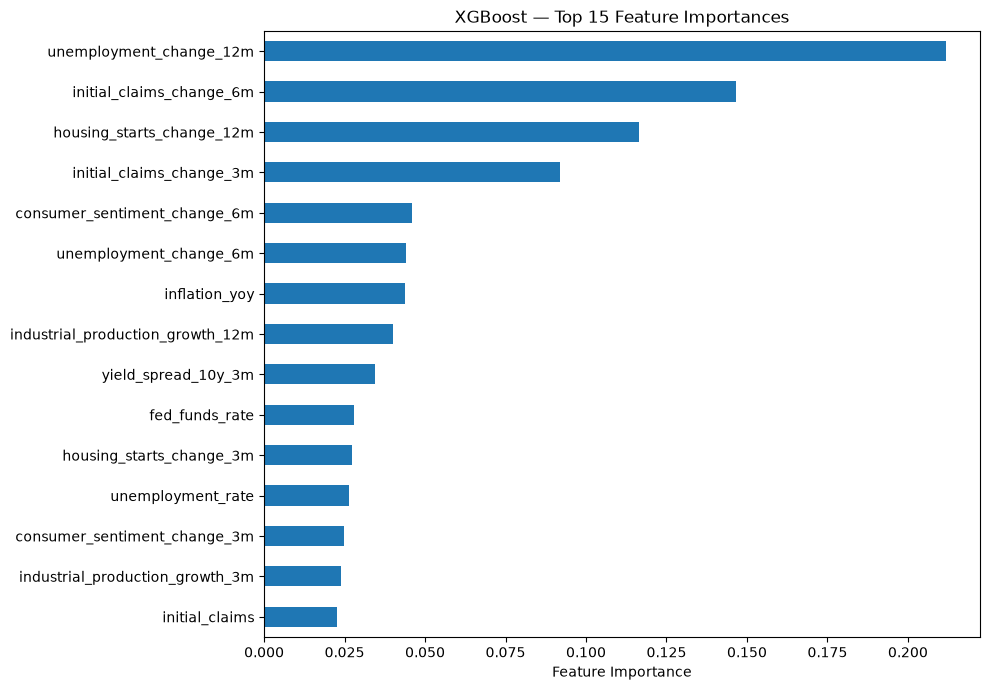

In [12]:
plt.figure(figsize=(10, 7))

xgb_importance.head(15).sort_values().plot(kind="barh")

plt.title("XGBoost — Top 15 Feature Importances")
plt.xlabel("Feature Importance")
plt.ylabel("")

plt.tight_layout()
plt.show()


## 6. Comparing Feature Importance Across Models

Different algorithms represent relationships differently. Logistic Regression assumes an additive linear relationship in log-odds, while Random Forest and XGBoost can model nonlinearities and interactions.

Therefore, disagreement between their importance measures is expected. Features that appear important across several model types are especially interesting, but agreement still does not establish causality.


In [13]:
importance_comparison = pd.DataFrame({
    "Logistic |coefficient|": pd.Series(
        logistic_model.named_steps["model"].coef_[0],
        index=X.columns
    ).abs(),
    "Random Forest": pd.Series(
        random_forest.feature_importances_,
        index=X.columns
    ),
    "XGBoost": pd.Series(
        xgb_model.feature_importances_,
        index=X.columns
    )
})

importance_comparison["Average rank"] = (
    importance_comparison[
        ["Logistic |coefficient|", "Random Forest", "XGBoost"]
    ]
    .rank(ascending=False)
    .mean(axis=1)
)

importance_comparison.sort_values("Average rank").head(15)


,Logistic |coefficient|,Random Forest,XGBoost,Average rank
unemployment_change_12m,1.823442,0.151516,0.211796,1.333333
housing_starts_change_12m,1.464871,0.106050,0.116398,3.333333
inflation_yoy,1.198388,0.068997,0.043683,5.666667
initial_claims_change_6m,0.410583,0.116177,0.146440,6.333333
consumer_sentiment_change_6m,0.933497,0.065904,0.046089,6.333333
yield_spread_10y_3m,1.669814,0.025918,0.034406,8.000000
industrial_production_growth_12m,0.863545,0.052018,0.040131,8.000000
initial_claims_change_3m,0.072921,0.079121,0.091961,9.000000
unemployment_rate,2.355369,0.021732,0.026279,9.000000
fed_funds_rate,0.680193,0.032649,0.028038,9.666667


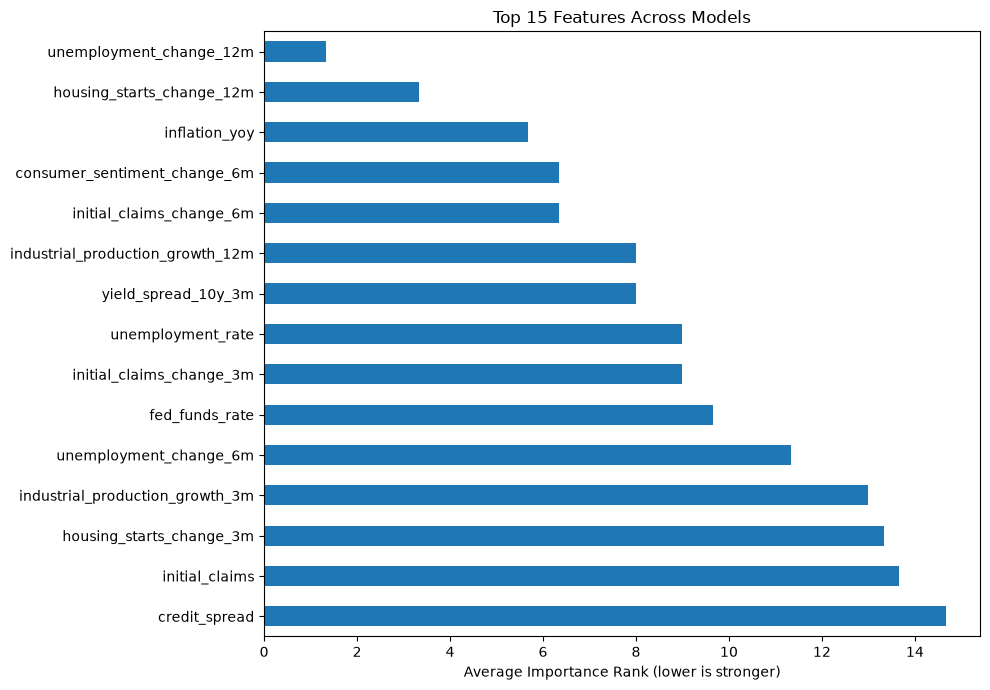

In [14]:
top_features = importance_comparison.sort_values("Average rank").head(15)

plt.figure(figsize=(10, 7))
top_features["Average rank"].sort_values(ascending=False).plot(kind="barh")
plt.title("Top 15 Features Across Models")
plt.xlabel("Average Importance Rank (lower is stronger)")
plt.ylabel("")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "feature_importance.png", dpi=300, bbox_inches="tight")
plt.show()


## 7. SHAP Interpretation of XGBoost

SHAP values provide a more detailed explanation of the XGBoost model. Instead of only reporting how important a feature is overall, SHAP estimates how each feature contributes to individual predictions.

The summary plot shows both:

- **importance:** features with larger absolute SHAP values have a greater influence on predictions;
- **direction:** the position of observations shows whether particular feature values push predicted recession risk higher or lower.

SHAP explains the behavior of the fitted model, not causal economic relationships.


In [15]:
if SHAP_AVAILABLE:
    explainer = shap.TreeExplainer(xgb_model)
    shap_values = explainer.shap_values(X_test)

    print("SHAP values shape:", np.asarray(shap_values).shape)
else:
    print("Install SHAP with: %pip install shap")


SHAP values shape: (94, 23)


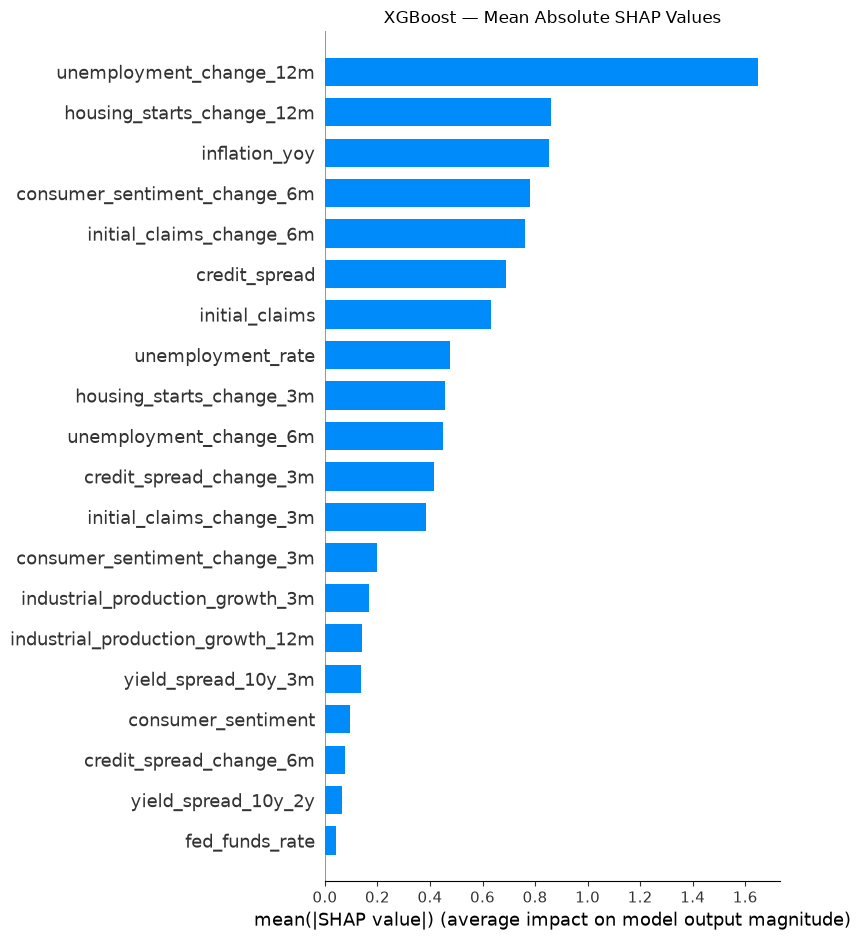

In [16]:
if SHAP_AVAILABLE:
    shap.summary_plot(
        shap_values,
        X_test,
        plot_type="bar",
        show=False
    )
    plt.title("XGBoost — Mean Absolute SHAP Values")
    plt.tight_layout()
    plt.show()


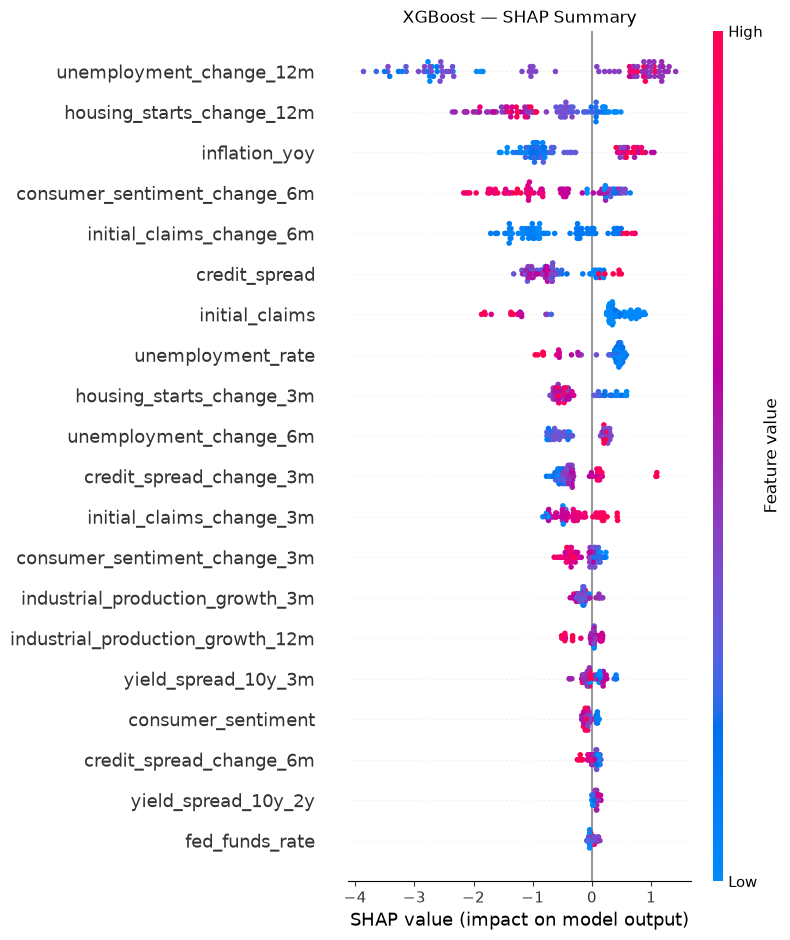

In [17]:
if SHAP_AVAILABLE:
    shap.summary_plot(
        shap_values,
        X_test,
        show=False
    )
    plt.title("XGBoost — SHAP Summary")
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / "shap_summary.png", dpi=300, bbox_inches="tight")
    plt.show()


## 8. Inspect the Holdout Recession Observations

Only two holdout observations have a positive six-month-ahead target. Examining their predicted probabilities helps explain the difference between Logistic Regression and the tree-based models.


In [18]:
holdout_predictions = pd.DataFrame({
    "Actual": y_test,
    "Logistic Regression": logistic_prob,
    "Random Forest": rf_prob,
    "XGBoost": xgb_prob
}, index=X_test.index)

holdout_recessions = holdout_predictions[
    holdout_predictions["Actual"] == 1
]

holdout_recessions


,Actual,Logistic Regression,Random Forest,XGBoost
2019-09-01,1,0.580994,0.088,0.002781
2019-10-01,1,0.738342,0.124,0.002289


In [19]:
holdout_recessions.round(3)


,Actual,Logistic Regression,Random Forest,XGBoost
2019-09-01,1,0.581,0.088,0.003
2019-10-01,1,0.738,0.124,0.002


Because the target represents recession status six months in the future, these dates are the predictor months rather than the months in which the recession itself occurs.

With only two positive observations, conclusions about general recession-detection ability from the holdout alone are highly uncertain. This is one reason the time-series cross-validation results are also important.


## 9. Probability Paths Around the Holdout Recession

The probability plot shows how model risk estimates changed through the holdout period rather than reducing every prediction to a binary 0/1 decision.


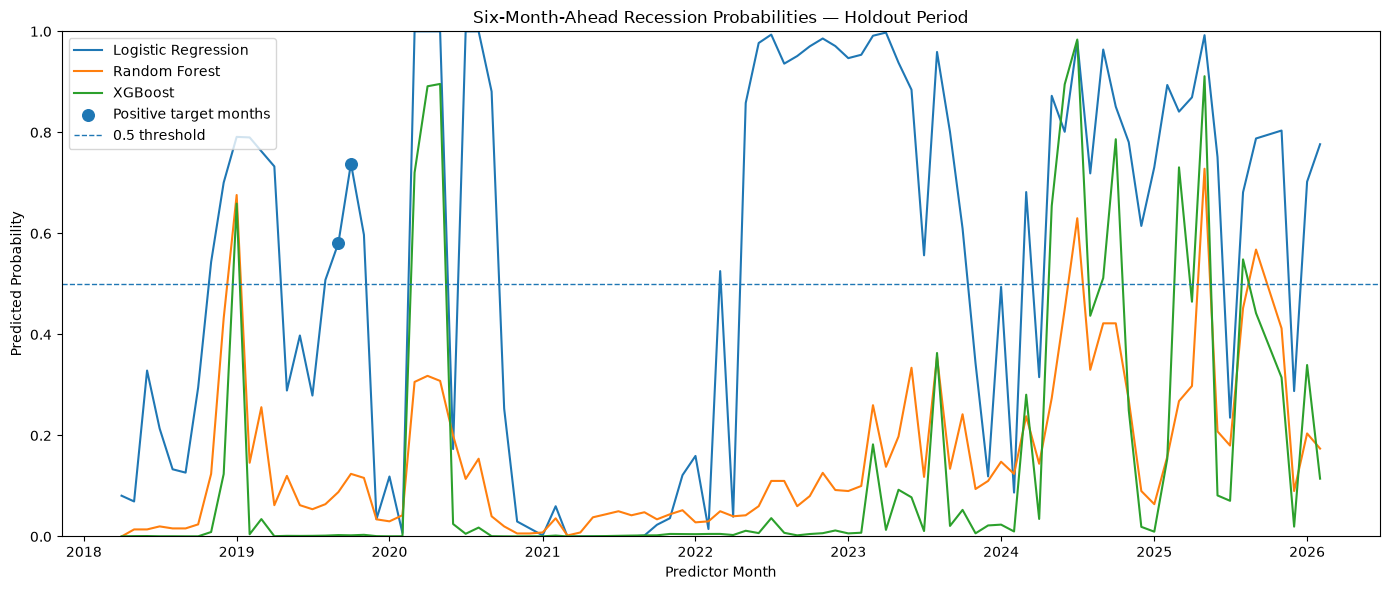

In [20]:
plt.figure(figsize=(14, 6))

plt.plot(
    holdout_predictions.index,
    holdout_predictions["Logistic Regression"],
    label="Logistic Regression"
)
plt.plot(
    holdout_predictions.index,
    holdout_predictions["Random Forest"],
    label="Random Forest"
)
plt.plot(
    holdout_predictions.index,
    holdout_predictions["XGBoost"],
    label="XGBoost"
)

plt.scatter(
    holdout_recessions.index,
    holdout_recessions["Logistic Regression"],
    marker="o",
    s=70,
    label="Positive target months"
)

plt.axhline(0.5, linestyle="--", linewidth=1, label="0.5 threshold")

plt.title("Six-Month-Ahead Recession Probabilities — Holdout Period")
plt.xlabel("Predictor Month")
plt.ylabel("Predicted Probability")
plt.ylim(0, 1)
plt.legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_probabilities.png", dpi=300, bbox_inches="tight")
plt.show()


## 10. Classification Threshold Analysis

The default classification threshold is 0.5, but this threshold is not inherently optimal for an imbalanced early-warning problem.

Lowering the threshold generally increases recall but can also create more false alarms. Raising it generally does the opposite.

The following analysis is **diagnostic only**. The holdout set must not be used to choose the final threshold and then be reported as an unbiased test result. A production workflow would select the threshold using training/validation data and evaluate it once on untouched future data.


In [21]:
def threshold_metrics(y_true, probabilities, thresholds):
    rows = []

    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)

        rows.append({
            "Threshold": threshold,
            "Precision": precision_score(
                y_true, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_true, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_true, predictions, zero_division=0
            ),
            "Predicted recession months": int(predictions.sum())
        })

    return pd.DataFrame(rows)


thresholds = np.arange(0.10, 0.91, 0.05)

logistic_thresholds = threshold_metrics(
    y_test, logistic_prob, thresholds
)
rf_thresholds = threshold_metrics(
    y_test, rf_prob, thresholds
)
xgb_thresholds = threshold_metrics(
    y_test, xgb_prob, thresholds
)

logistic_thresholds.head()


,Threshold,Precision,Recall,F1,Predicted recession months
0,0.10,0.027027,1.0,0.052632,74
1,0.15,0.028986,1.0,0.056338,69
2,0.20,0.029851,1.0,0.057971,67
3,0.25,0.030769,1.0,0.059701,65
4,0.30,0.033333,1.0,0.064516,60


In [22]:
threshold_comparison = pd.concat([
    logistic_thresholds.assign(Model="Logistic Regression"),
    rf_thresholds.assign(Model="Random Forest"),
    xgb_thresholds.assign(Model="XGBoost")
], ignore_index=True)

threshold_comparison


,Threshold,Precision,Recall,F1,Predicted recession months,Model
0,0.10,0.027027,1.0,0.052632,74,Logistic Regression
1,0.15,0.028986,1.0,0.056338,69,Logistic Regression
2,0.20,0.029851,1.0,0.057971,67,Logistic Regression
3,0.25,0.030769,1.0,0.059701,65,Logistic Regression
4,0.30,0.033333,1.0,0.064516,60,Logistic Regression
5,0.35,0.035088,1.0,0.067797,57,Logistic Regression
6,0.40,0.035714,1.0,0.068966,56,Logistic Regression
7,0.45,0.035714,1.0,0.068966,56,Logistic Regression
8,0.50,0.036364,1.0,0.070175,55,Logistic Regression
9,0.55,0.038462,1.0,0.074074,52,Logistic Regression


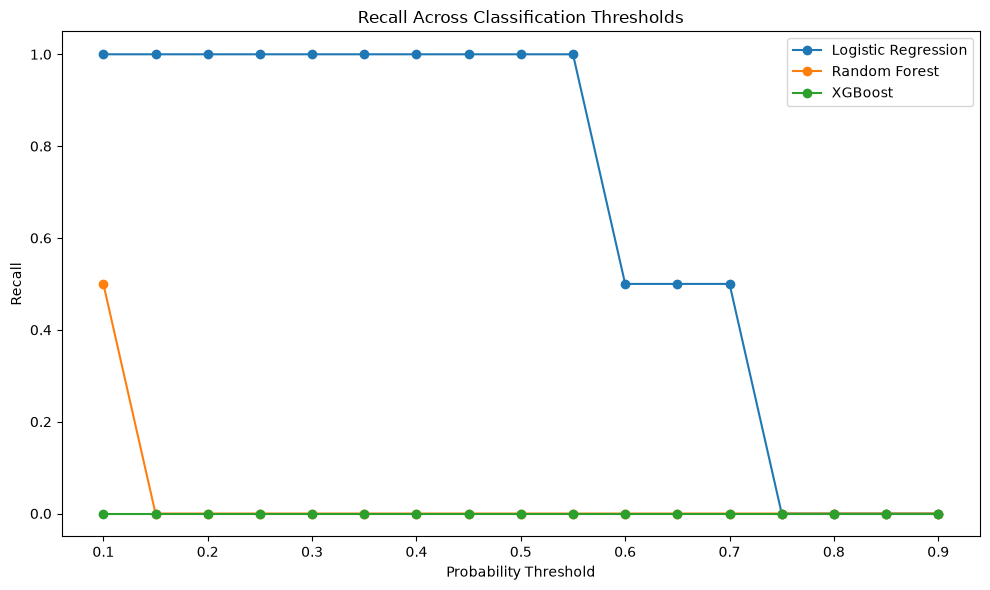

In [23]:
plt.figure(figsize=(10, 6))

for model_name, group in threshold_comparison.groupby("Model"):
    plt.plot(
        group["Threshold"],
        group["Recall"],
        marker="o",
        label=model_name
    )

plt.title("Recall Across Classification Thresholds")
plt.xlabel("Probability Threshold")
plt.ylabel("Recall")
plt.ylim(-0.05, 1.05)
plt.legend()

plt.tight_layout()
plt.show()


The threshold analysis illustrates the trade-off between detecting recession observations and generating false alarms. Because the holdout contains only two positive observations, these curves are especially sensitive to individual months and should not be treated as robust threshold optimization.


## 11. Why the 2020 Episode Is Difficult

The holdout evaluation is dominated by the 2020 recession episode, while the models were trained primarily on earlier recessions.

This creates several challenges:

1. **Very few positive observations.** The holdout contains only two positive six-month-ahead targets.
2. **Different recession dynamics.** Relationships learned from earlier downturns may not transfer to a sudden economic shock.
3. **Exact-horizon target.** The current target asks whether the economy is in recession exactly six months later. A short recession therefore creates very few positive training or test labels.
4. **Class imbalance.** Across the complete engineered dataset, only 36 of 469 observations are positive recession targets.
5. **Model instability across periods.** Cross-validation performance changes substantially across folds, showing that predictive relationships are not stable through time.

These limitations help explain why high overall accuracy did not translate into reliable recession detection.


## 12. Limitations

Several limitations are important when interpreting the project:

### Limited number of recession episodes

Although the dataset spans several decades, it contains only a small number of distinct recessions. Monthly observations within one recession are also not independent economic events.

### Exact six-month target

The model predicts whether the economy is in recession exactly six months later. An alternative early-warning formulation could ask whether a recession will occur at any point within the next six months. That would answer a different research question and could be investigated as an extension.

### Revised historical data

The project uses currently available historical FRED data. Many macroeconomic series are revised after their original release, so the model may use values that differ from what a real forecaster would have observed at the time.

A stricter real-time forecasting study would use historical data vintages, for example through ALFRED, and explicitly account for publication lags.

### Publication timing

Some monthly indicators are released after the month they describe. Treating all month-*t* observations as simultaneously available can therefore make the information set more optimistic than a real-time forecasting environment.

### Model and threshold uncertainty

The small number of positive events makes model comparison and threshold selection unstable. The results should therefore be interpreted as an exploratory machine-learning study rather than evidence of a production-ready recession forecasting system.


## 13. Conclusions

This project tested whether a set of U.S. macroeconomic indicators could predict recession status six months in advance using Logistic Regression, Random Forest and XGBoost.

The results demonstrate why recession forecasting is a difficult imbalanced classification problem. The majority-class baseline achieved approximately 97.9% accuracy on the chronological holdout while identifying no recessions, showing that accuracy alone is misleading.

Logistic Regression detected both positive holdout observations, giving a recall of 1.0, but produced many false positives and only about 3.6% precision. Random Forest and XGBoost produced fewer recession classifications at the default threshold but missed both positive holdout observations.

Time-series cross-validation showed that performance varied considerably across historical periods. Random Forest and XGBoost performed relatively strongly in one validation fold but poorly in another, while two folds could not support all classification metrics because their validation periods contained only one class.

The main conclusion is therefore not that one algorithm consistently solves recession forecasting. Instead, the experiment shows that model performance is highly sensitive to the recession episode, target definition, class imbalance and evaluation period.

Feature importance, model coefficients and SHAP analysis provide a way to examine which economic indicators influence the fitted models, while the instability of predictive performance highlights the importance of temporal validation and cautious interpretation.

A natural extension would redefine the target as whether a recession occurs **within** the next three, six or twelve months and compare forecasting horizons using a real-time data framework with historical vintages.
